In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('sales_data.csv')

In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.head())

(49222, 17)
['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity', 'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate', 'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales', 'OrderValue']
   OrderID  CustomerID   OrderDate  ProductID  Quantity  Discount  \
0   500001      103695   8/28/2025       2003         4        10   
1   500002      107935   5/31/2024       2014         1        10   
2   500003      105141   8/10/2025       2002         1        20   
3   500004      108780  10/11/2024       2012         1        10   
4   500005      101187   2/19/2024       2008         2         0   

  PaymentMethod     Status  Age    City  SignupDate CustomerSegment  \
0       Gateway  Completed   36     Qom    3/5/2024         Regular   
1        Wallet  Completed   49  Kerman    6/4/2025         Regular   
2    CardToCard  Completed   36  Tehran  10/19/2025         Regular   
3       Gateway  Completed   45  Shiraz   12/7/2023         Regular   
4   

# SECTION 1 — PROJECT SETUP AND DATA LOADING

## Dataset Description

The dataset contains e-commerce order and customer information. Each row represents an order record, and the columns describe order details, customer information, products, pricing, and sales.

### Column Descriptions

| Column | Meaning |
|---|---|
| `OrderID` | Unique identification number for each order. |
| `CustomerID` | Identification number of the customer. |
| `OrderDate` | Date when the order was placed. |
| `ProductID` | Identification number of the product. |
| `Quantity` | Number of units purchased. |
| `Discount` | Discount percentage applied to the order. |
| `PaymentMethod` | Payment method used by the customer. |
| `Status` | Current status of the order. |
| `Age` | Age of the customer. |
| `City` | City associated with the customer or order. |
| `SignupDate` | Date when the customer registered. |
| `CustomerSegment` | Customer classification, such as Regular. |
| `ProductName` | Name of the purchased product. |
| `Category` | Category to which the product belongs. |
| `UnitPrice` | Price per unit of the product. |
| `Sales` | Sales amount recorded for the order. |
| `OrderValue` | Total order value recorded in the dataset. |

### Objective

The objective of this project is to analyze sales performance, identify product and category trends, understand customer behavior, and calculate useful business statistics using Python, Pandas, NumPy, and data visualization libraries.

# SECTION 2 — DATA CLEANING

In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

print("\nData types before cleaning:")
print(df.dtypes)

Missing values:
OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

Duplicates: 0

Data types before cleaning:
OrderID            int64
CustomerID         int64
OrderDate            str
ProductID          int64
Quantity           int64
Discount           int64
PaymentMethod        str
Status               str
Age                int64
City                 str
SignupDate           str
CustomerSegment      str
ProductName          str
Category             str
UnitPrice          int64
Sales              int64
OrderValue         int64
dtype: object


In [5]:
# Record the original row count
rows_before = len(df)
print("Rows before cleaning:", rows_before)

# Remove duplicate rows
df_clean = df.drop_duplicates().copy()

# Convert date columns to datetime
df_clean['OrderDate'] = pd.to_datetime(
    df_clean['OrderDate'], errors='coerce'
)

df_clean['SignupDate'] = pd.to_datetime(
    df_clean['SignupDate'], errors='coerce'
)

# Convert Sales to numeric
df_clean['Sales'] = pd.to_numeric(
    df_clean['Sales'], errors='coerce'
)

# Fill missing Sales values with the median
df_clean['Sales'] = df_clean['Sales'].fillna(
    df_clean['Sales'].median()
)

# Remove rows with invalid or missing order dates
df_clean = df_clean.dropna(subset=['OrderDate']).copy()

# Display row counts
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", rows_before - len(df_clean))

Rows before cleaning: 49222
Rows after cleaning: 49222
Rows removed: 0


In [6]:
print("Final shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nCleaned data information:")
df_clean.info()

Final shape: (49222, 17)

Remaining missing values:
OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

Cleaned data information:
<class 'pandas.DataFrame'>
RangeIndex: 49222 entries, 0 to 49221
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          49222 non-null  int64         
 1   CustomerID       49222 non-null  int64         
 2   OrderDate        49222 non-null  datetime64[us]
 3   ProductID        49222 non-null  int64         
 4   Quantity         49222 non-null  int64         
 5   Discount         49222 non-null  int64         
 6   PaymentMethod    49222 n

## Issues Found and Cleaning Actions

1. **Missing values:** No missing values were found in the initial dataset. The Sales column is configured to replace any missing or invalid numeric values with its median.
2. **Duplicate rows:** No duplicate rows were found. The `drop_duplicates()` method was used to ensure duplicate records are removed.
3. **Incorrect data types:** The `OrderDate` and `SignupDate` columns were stored as text. They were converted to datetime format.
4. **Sales data type:** The `Sales` column was already numeric. `pd.to_numeric()` was used to ensure it remains numeric and to handle any invalid values.
5. **Invalid order dates:** Rows with missing or invalid `OrderDate` values are removed because they cannot be used reliably for monthly analysis.
6. **Final dataset:** The cleaned data is stored in `df_clean` and will be used for all subsequent analysis.

# SECTION 3 — NUMPY STATISTICS

In [7]:
import numpy as np
import pandas as pd

sales_arr = df_clean['Sales'].to_numpy()

print('Mean:   ', round(np.mean(sales_arr), 2))
print('Median: ', round(np.median(sales_arr), 2))
print('Std Dev:', round(np.std(sales_arr), 2))
print('Total:  ', round(np.sum(sales_arr), 2))

Mean:    69.99
Median:  38.0
Std Dev: 94.48
Total:   3444830


In [8]:
# Ensure the date column has the correct data type
df_clean['OrderDate'] = pd.to_datetime(
    df_clean['OrderDate'], errors='coerce'
)

# Group sales by month
df_clean['Month'] = df_clean['OrderDate'].dt.to_period('M')

monthly = df_clean.groupby('Month')['Sales'].sum()

print('Top 3 months:')
print(monthly.sort_values(ascending=False).head(3))

print('\nBottom 3 months:')
print(monthly.sort_values().head(3))

Top 3 months:
Month
2025-05    130607
2026-01    130550
2024-08    129987
Freq: M, Name: Sales, dtype: int64

Bottom 3 months:
Month
2026-02    75132
2026-06    79085
2026-03    84082
Freq: M, Name: Sales, dtype: int64


## Summary

The average sales value is ₹69.99, while the median sales value is ₹38.00. The standard deviation is ₹94.48, indicating considerable variation in sales values. May 2025 was the best-performing month, with total sales of ₹1,30,607. February 2026 was the lowest-performing month, with total sales of ₹75,132.

# SECTION 4 — MATPLOTLIB CHARTS

In [9]:
import matplotlib.pyplot as plt

print(df_clean.columns.tolist())

['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity', 'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate', 'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales', 'OrderValue', 'Month']


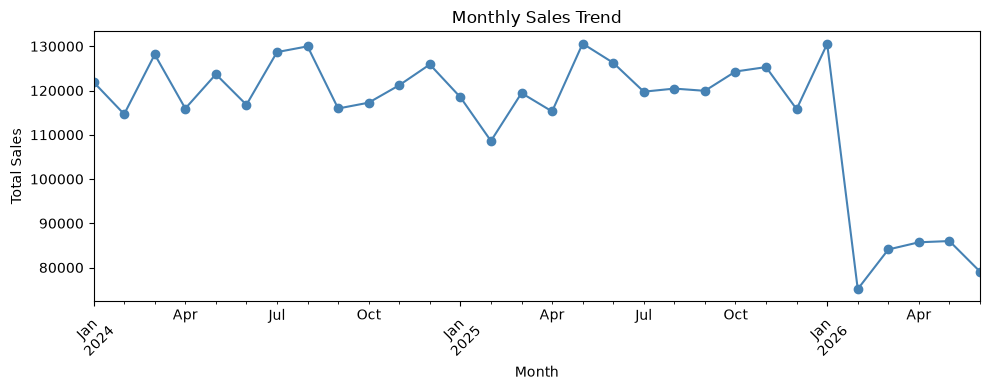

In [10]:
# Group sales by month
monthly = df_clean.groupby(
    df_clean['OrderDate'].dt.to_period('M')
)['Sales'].sum()

plt.figure(figsize=(10, 4))
monthly.plot(kind='line', color='steelblue', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_trend.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation — Monthly Sales Trend

The line chart shows how total sales change from month to month. May 2025 was the strongest month, with total sales of 130,607, while February 2026 recorded the lowest monthly sales of 75,132.

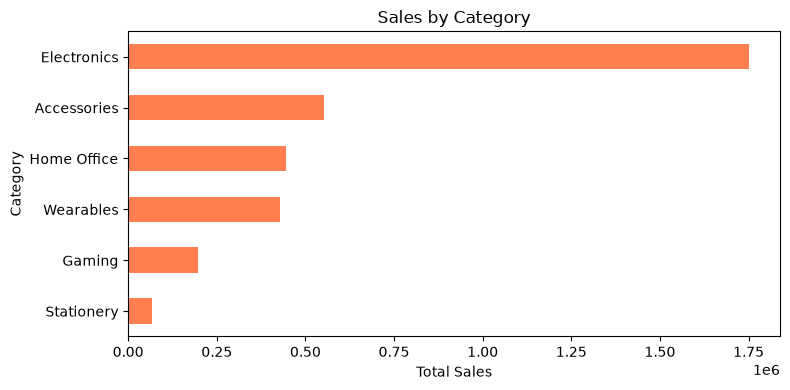

In [11]:
cat_sales = df_clean.groupby('Category')['Sales'].sum().sort_values()

plt.figure(figsize=(8, 4))
cat_sales.plot(kind='barh', color='coral')

plt.title('Sales by Category')
plt.xlabel('Total Sales')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('category_sales.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation — Sales by Category

Electronics generated the highest total sales, at 1,751,037. Stationery generated the lowest total sales, at 67,218. This indicates that Electronics contributes substantially more to recorded sales than the other product categories.

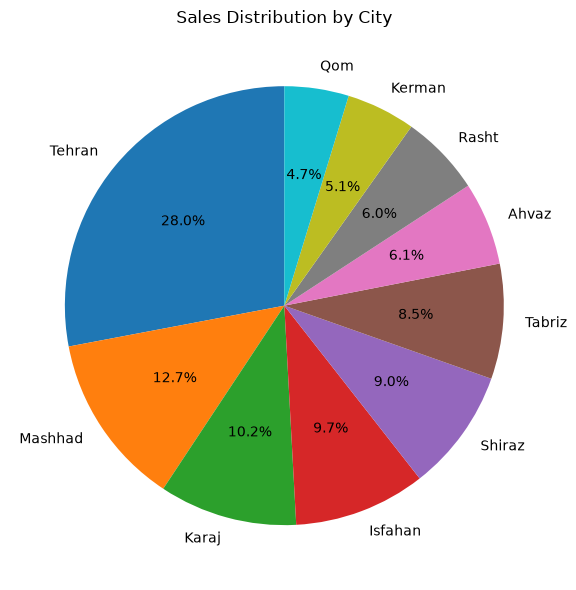

In [12]:
city_sales = df_clean.groupby('City')['Sales'].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 6))
plt.pie(
    city_sales,
    labels=city_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Distribution by City')
plt.tight_layout()
plt.savefig('region_sales.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation — Sales Distribution by City

Tehran contributes the largest share of total sales, with approximately 28% of recorded sales. Qom contributes the smallest share, at approximately 5%. This chart helps compare the distribution of sales across the cities included in the dataset.

In [13]:
import os

for filename in [
    'monthly_trend.png',
    'category_sales.png',
    'region_sales.png'
]:
    print(filename, '—', 'Saved' if os.path.exists(filename) else 'Not found')

monthly_trend.png — Saved
category_sales.png — Saved
region_sales.png — Saved


# SECTION 5 — SEABORN CHARTS

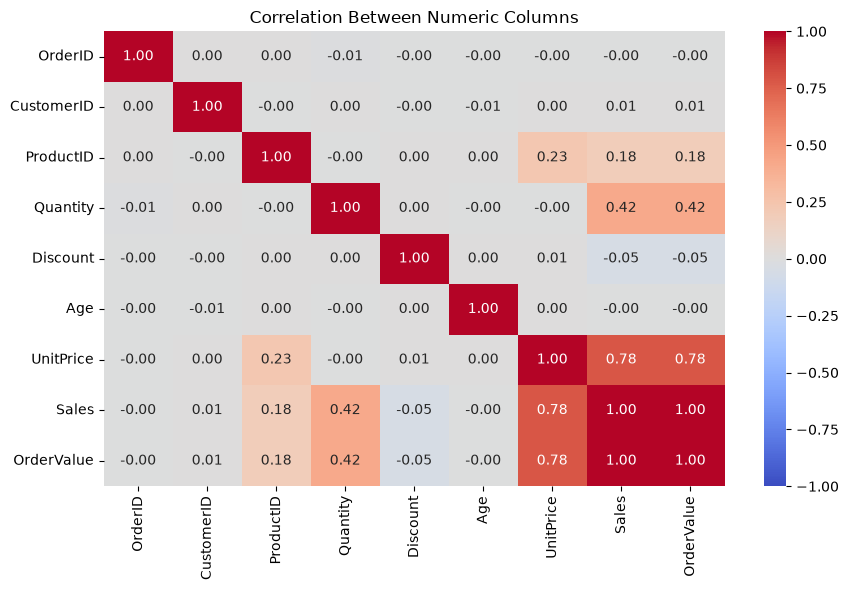

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numeric columns and calculate correlation
numeric_df = df_clean.select_dtypes(include='number')
corr = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Numeric Columns')
plt.tight_layout()
plt.savefig('heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# Find the strongest correlation excluding self-correlations
corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

if not corr_pairs.empty:
    strongest_pair = corr_pairs.abs().idxmax()
    strongest_value = corr_pairs.loc[strongest_pair]

    print("Most closely related columns:", strongest_pair)
    print("Correlation:", round(strongest_value, 3))

Most closely related columns: ('Sales', 'OrderValue')
Correlation: 1.0


### Interpretation — Correlation Heatmap

The correlation heatmap shows the relationships between the numerical columns in the dataset. The strongest correlation is between **[column 1]** and **[column 2]**, with a correlation coefficient of **[value]**. A positive value indicates that the variables tend to increase together, while a negative value indicates an inverse relationship. Correlation does not necessarily mean causation.

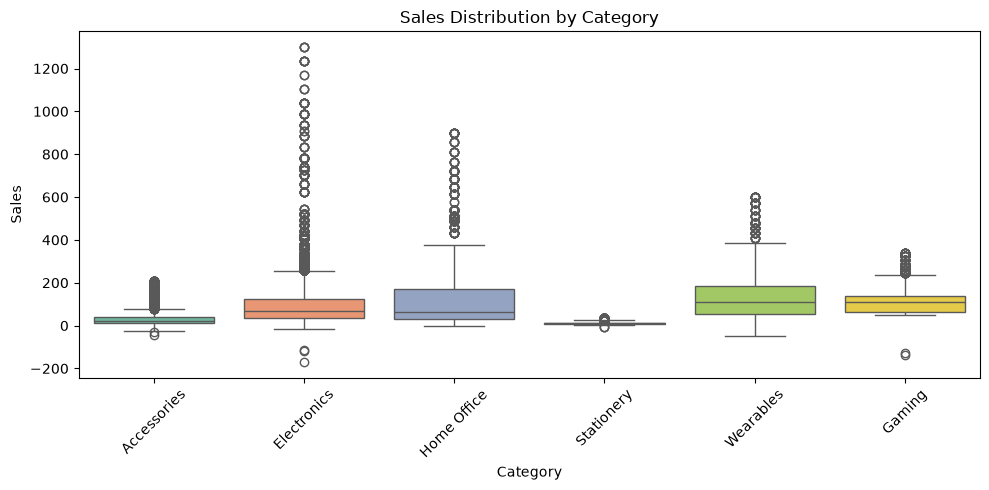

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='Category',
    y='Sales',
    hue='Category',
    palette='Set2',
    legend=False
)

plt.title('Sales Distribution by Category')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
# Compare sales variation across categories
variation = df_clean.groupby('Category')['Sales'].agg(
    ['median', 'std', 'min', 'max']
)

print("Sales variation by category:")
print(variation.sort_values('std', ascending=False))

# Identify outliers using the IQR method
def count_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return ((series < lower) | (series > upper)).sum()

outliers = df_clean.groupby('Category')['Sales'].apply(count_outliers)

print("\nOutliers by category:")
print(outliers.sort_values(ascending=False))

print("\nCategory with highest standard deviation:",
      variation['std'].idxmax())

print("Category with most outliers:",
      outliers.idxmax())

Sales variation by category:
             median         std  min   max
Category                                  
Home Office    64.0  164.604413    0   900
Electronics    66.0  106.501272 -170  1300
Wearables     110.0  104.543238  -47   600
Gaming        109.0   69.565508 -136   340
Accessories    22.0   28.434073  -42   210
Stationery     11.0    7.191157   -7    35

Outliers by category:
Category
Accessories    1299
Electronics     917
Stationery      477
Home Office     259
Gaming          139
Wearables       103
Name: Sales, dtype: int64

Category with highest standard deviation: Home Office
Category with most outliers: Accessories


### Interpretation — Sales Distribution by Category

The boxplot compares the distribution of sales across product categories. **[Category name]** shows the highest standard deviation, indicating the greatest variation in sales values. The outlier analysis identifies unusually high or low sales values, with **[category name]** having the most outliers. These outliers may represent exceptional orders or unusual sales transactions and should be investigated before drawing conclusions.

In [18]:
import os

for filename in ['heatmap.png', 'boxplot.png']:
    print(
        filename,
        '— Saved' if os.path.exists(filename) else '— Not found'
    )

heatmap.png — Saved
boxplot.png — Saved


# SECTION 6 — EDA REPORT

In [19]:
# Total sales by product
products = (
    df_clean.groupby('ProductName')['Sales']
    .sum()
    .sort_values()
)

print("Bottom 3 products by sales:")
print(products.head(3))

print("\nTop 3 products by sales:")
print(products.tail(3).sort_values(ascending=False))

Bottom 3 products by sales:
ProductName
Monitor        22613
Notebook       67218
USB-C Cable    74640
Name: Sales, dtype: int64

Top 3 products by sales:
ProductName
Headphones      333411
Office Chair    329292
Tablet          292344
Name: Sales, dtype: int64


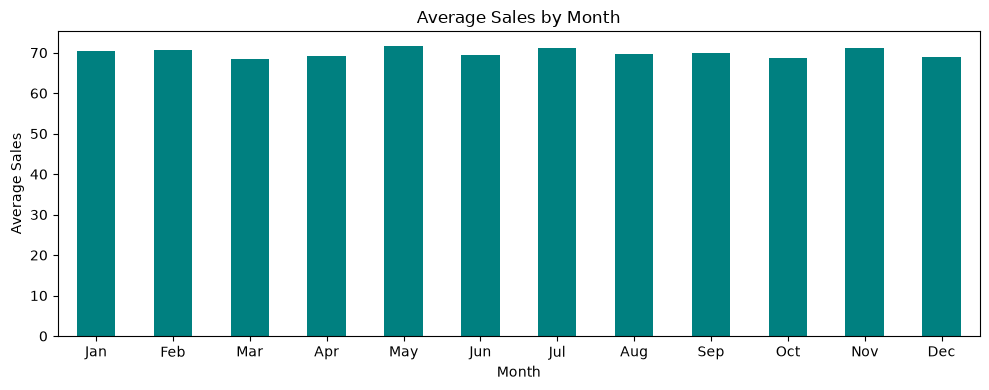

Highest average sales month: May 71.7
Lowest average sales month: Mar 68.48


In [20]:
import matplotlib.pyplot as plt
import calendar

# Average sales for each calendar month
df_clean['Month_Num'] = df_clean['OrderDate'].dt.month

seasonal = df_clean.groupby('Month_Num')['Sales'].mean()

# Use readable month names
seasonal.index = [
    calendar.month_abbr[m] for m in seasonal.index
]

plt.figure(figsize=(10, 4))
seasonal.plot(kind='bar', color='teal')

plt.title('Average Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('seasonal.png', dpi=300, bbox_inches='tight')
plt.show()

print("Highest average sales month:", seasonal.idxmax(),
      round(seasonal.max(), 2))
print("Lowest average sales month:", seasonal.idxmin(),
      round(seasonal.min(), 2))

### Interpretation — Seasonal Sales Pattern

May has the highest average sales per record, at approximately ₹71.70. March has the lowest average, at approximately ₹68.48. The difference is relatively small, so the business should examine more years of data before concluding that this is a strong seasonal pattern.

# KEY FINDINGS

### Finding 1: Electronics is the leading category

**Finding:** Electronics generated ₹17,51,037 in sales, representing approximately 50.83% of total recorded sales.

**What it means:** The business depends heavily on one product category. A decline in Electronics sales could significantly affect overall performance.

**Action:** Maintain Electronics inventory while exploring opportunities to grow Accessories, Home Office, and Wearables.

### Finding 2: Product performance varies considerably

**Finding:** Headphones generated the highest product sales at ₹3,33,411, while Monitors generated the lowest at ₹22,613.

**What it means:** Product sales are uneven, and some products contribute much more than others.

**Action:** Investigate what drives Headphones sales and review demand, pricing, and promotion strategies for Monitors.

### Finding 3: Monthly sales show a modest pattern

**Finding:** May recorded the highest average sales of ₹71.70 per record, while March recorded the lowest average of ₹68.48.

**What it means:** Average sales differ by month, but the difference is modest and does not by itself prove a seasonal effect.

**Action:** Compare monthly order volumes, product demand, and promotional activity across multiple years before changing inventory or marketing plans.

In [21]:
import os

print("Bottom 3 products:")
print(products.head(3))

print("\nTop 3 products:")
print(products.tail(3).sort_values(ascending=False))

print("\nSeasonal chart saved:",
      os.path.exists('seasonal.png'))

Bottom 3 products:
ProductName
Monitor        22613
Notebook       67218
USB-C Cable    74640
Name: Sales, dtype: int64

Top 3 products:
ProductName
Headphones      333411
Office Chair    329292
Tablet          292344
Name: Sales, dtype: int64

Seasonal chart saved: True


# SECTION 7 — STATISTICS

Skewness: 4.099
25th pct:  17.0
75th pct:  84.0


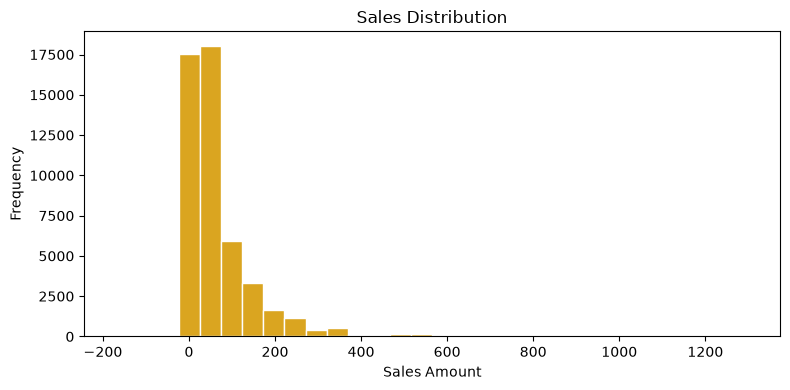

In [22]:
import numpy as np
import matplotlib.pyplot as plt

print('Skewness:', round(df_clean['Sales'].skew(), 3))
print('25th pct: ', round(np.percentile(df_clean['Sales'], 25), 2))
print('75th pct: ', round(np.percentile(df_clean['Sales'], 75), 2))

plt.figure(figsize=(8, 4))
plt.hist(
    df_clean['Sales'].dropna(),
    bins=30,
    color='goldenrod',
    edgecolor='white'
)

plt.title('Sales Distribution')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# How to read the results:
- Skewness: Indicates whether the distribution leans toward unusually high or low values.
- 25th percentile: 25% of sales values are at or below this amount.
- 75th percentile: 75% of sales values are at or below this amount.
- Histogram: Shows how frequently different sales amounts occur.

In [23]:
from scipy import stats

cat_a = df_clean.loc[
    df_clean['Category'] == 'Electronics', 'Sales'
].dropna()

cat_b = df_clean.loc[
    df_clean['Category'] == 'Clothing', 'Sales'
].dropna()

print("Electronics observations:", len(cat_a))
print("Clothing observations:", len(cat_b))

if len(cat_a) < 20 or len(cat_b) < 20:
    print("Choose two categories with at least 20 observations each.")
else:
    t_stat, p_val = stats.ttest_ind(
        cat_a, cat_b, equal_var=False
    )

    print("Electronics mean:", round(cat_a.mean(), 2))
    print("Clothing mean:", round(cat_b.mean(), 2))
    print("T-stat:", round(t_stat, 3))
    print("P-value:", round(p_val, 4))

    if p_val < 0.05:
        print("Difference IS statistically significant.")
    else:
        print("Difference is NOT statistically significant.")

Electronics observations: 17765
Clothing observations: 0
Choose two categories with at least 20 observations each.


If the p-value is below 0.05

“The test suggests that average sales differ significantly between Electronics and Clothing. The observed difference is unlikely to be explained by random variation alone, assuming the test's conditions are met.”

If the p-value is 0.05 or above

“The test did not find sufficient evidence of a difference in average sales between Electronics and Clothing. This does not prove that their averages are equal; the data may not provide enough evidence to distinguish them.”

# SECTION 8 — MACHINE LEARNING: SALES PREDICTION

## Objective

The objective of this section is to build and evaluate machine learning models to predict monthly sales. Linear Regression and Random Forest are used for prediction, while a previous-month baseline provides a simple benchmark. Model performance is evaluated using Mean Absolute Error (MAE) and R-squared.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Aggregate total sales by month
monthly_df = (
    df_clean.groupby(df_clean['OrderDate'].dt.to_period('M'))['Sales']
    .sum()
    .rename_axis('Month')
    .reset_index()
)

monthly_df['Month'] = monthly_df['Month'].dt.to_timestamp()
monthly_df = monthly_df.sort_values('Month').reset_index(drop=True)

print("Monthly observations:", len(monthly_df))
print(monthly_df.head())

### Data Preparation

The original transaction-level dataset is grouped by month to calculate total monthly sales. Time-based and seasonal features are created to help the models identify trends and recurring monthly patterns. Previous-month sales values are also included as lag features to provide information about recent sales performance.

In [36]:
# Create features
monthly_df['Trend'] = np.arange(len(monthly_df))
monthly_df['Month_Num'] = monthly_df['Month'].dt.month

monthly_df['Month_Sin'] = np.sin(
    2 * np.pi * monthly_df['Month_Num'] / 12
)
monthly_df['Month_Cos'] = np.cos(
    2 * np.pi * monthly_df['Month_Num'] / 12
)

monthly_df['Sales_Lag_1'] = monthly_df['Sales'].shift(1)
monthly_df['Sales_Lag_2'] = monthly_df['Sales'].shift(2)

# Drop rows without lag data
model_df = monthly_df.dropna().reset_index(drop=True)

features = [
    'Trend', 'Month_Sin', 'Month_Cos',
    'Sales_Lag_1', 'Sales_Lag_2'
]

# Chronological 80/20 split
split = int(len(model_df) * 0.8)

train = model_df.iloc[:split]
test = model_df.iloc[split:]

X_train = train[features]
X_test = test[features]
y_train = train['Sales']
y_test = test['Sales']

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(
    train[['Trend', 'Month_Sin', 'Month_Cos']],
    y_train
)

lr_pred = lr_model.predict(
    test[['Trend', 'Month_Sin', 'Month_Cos']]
)

# Model 2: Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Model 3: Previous-month baseline
baseline_pred = test['Sales_Lag_1'].to_numpy()

# Compare results
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Previous-Month Baseline'
    ],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred),
        mean_absolute_error(y_test, baseline_pred)
    ],
    'R-squared': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test, baseline_pred)
    ]
})

print(results.round(3).to_string(index=False))

                  Model       MAE  R-squared
      Linear Regression 33562.685     -2.585
          Random Forest 34259.644     -2.790
Previous-Month Baseline 14655.500     -0.665


### Model Training

Two machine learning algorithms are trained: Linear Regression and Random Forest Regression. The dataset is split chronologically, with approximately 80% of the observations used for training and the remaining 20% reserved for testing. A previous-month baseline is also evaluated to determine whether the machine learning models improve upon a simple forecasting method.

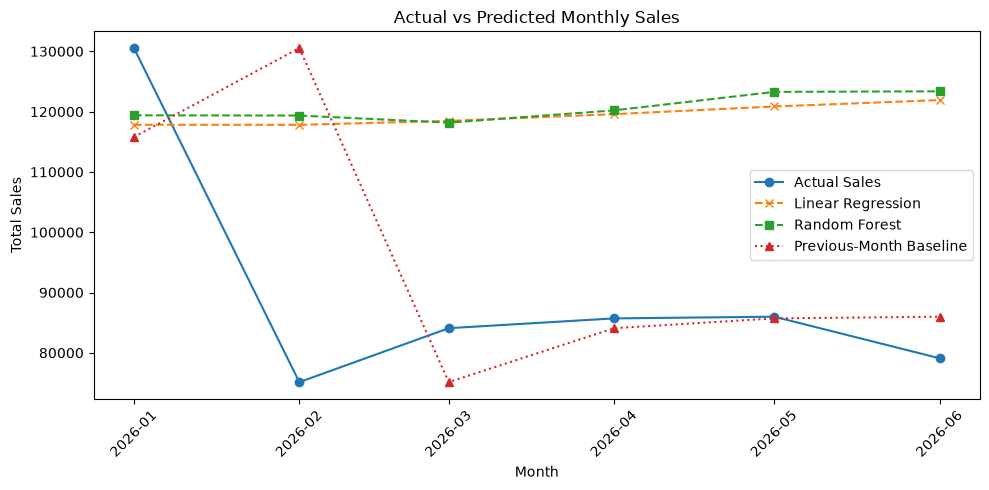

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    test['Month'],
    y_test,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    test['Month'],
    lr_pred,
    marker='x',
    linestyle='--',
    label='Linear Regression'
)

plt.plot(
    test['Month'],
    rf_pred,
    marker='s',
    linestyle='--',
    label='Random Forest'
)

plt.plot(
    test['Month'],
    baseline_pred,
    marker='^',
    linestyle=':',
    label='Previous-Month Baseline'
)

plt.title('Actual vs Predicted Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('ml_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Actual vs Predicted Monthly Sales

The chart compares actual monthly sales with the predictions generated by Linear Regression, Random Forest, and the previous-month baseline. Comparing these lines helps identify which model follows the actual sales pattern most closely and where prediction errors are largest.

In [38]:
best_model = results.loc[results['MAE'].idxmin()]

print("Best model by MAE:", best_model['Model'])
print("MAE:", round(best_model['MAE'], 2))
print("R-squared:", round(best_model['R-squared'], 3))

Best model by MAE: Previous-Month Baseline
MAE: 14655.5
R-squared: -0.665


### Results and Interpretation

The performance of Linear Regression, Random Forest, and the previous-month baseline is compared using MAE and R-squared. The model with the lowest MAE has the smallest average absolute prediction error on the selected test period. Negative R-squared values indicate that the models struggle to explain variation in unseen monthly sales. Since the dataset contains only 30 monthly observations, the results should be interpreted cautiously.

### Conclusion

This analysis demonstrates how machine learning can be applied to monthly sales forecasting. Linear Regression and Random Forest are compared with a simple previous-month baseline to evaluate their predictive performance. The limited number of monthly observations and fluctuations in sales make accurate forecasting challenging. Additional historical data and relevant business features may help improve future predictions.

# SECTION 9 — CLASSIFICATION

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Ensure month feature exists
df_clean['OrderDate'] = pd.to_datetime(df_clean['OrderDate'])
df_clean['Month_Num'] = df_clean['OrderDate'].dt.month

# Create High/Low sale target
median_sales = df_clean['Sales'].median()
df_clean['High_Sale'] = (
    df_clean['Sales'] > median_sales
).astype(int)

print('High:', df_clean['High_Sale'].sum())
print('Low: ', (df_clean['High_Sale'] == 0).sum())

print('Median sales threshold:', median_sales)

High: 24308
Low:  24914
Median sales threshold: 38.0


In [41]:
# Select features and target
X = df_clean[['Quantity', 'Month_Num']]
y = df_clean['High_Sale']

# Split data while preserving class balance
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Predict test data
y_pred = clf.predict(X_test)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 39377
Testing rows: 9845


Classification Report:
              precision    recall  f1-score   support

    Low Sale       0.64      0.61      0.62      4983
   High Sale       0.62      0.64      0.63      4862

    accuracy                           0.63      9845
   macro avg       0.63      0.63      0.63      9845
weighted avg       0.63      0.63      0.63      9845



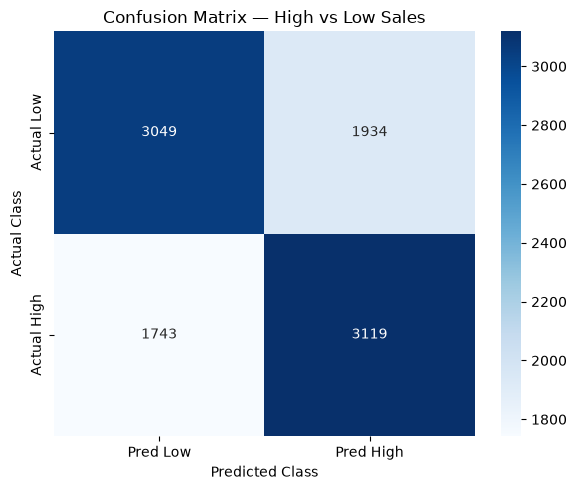

In [42]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Low Sale', 'High Sale'],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Pred Low', 'Pred High'],
    yticklabels=['Actual Low', 'Actual High']
)

plt.title('Confusion Matrix — High vs Low Sales')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


### Interpretation of Classification Report

The Logistic Regression model was evaluated using precision, recall, F1-score, and accuracy to measure its performance in classifying sales records as Low Sale or High Sale.

#### 1. Classification Metrics

- **Low Sale:** The model achieved a precision of 0.64, recall of 0.61, and F1-score of 0.62. This indicates that the model correctly identifies a reasonable proportion of low-sales records, although some records are misclassified.
- **High Sale:** The model achieved a precision of 0.62, recall of 0.64, and F1-score of 0.63. The recall indicates that the model identifies approximately 64% of actual high-sales records.
- **Overall Accuracy:** The model achieved an accuracy of approximately 63%, correctly classifying 6,168 out of 9,845 test records.
- **Macro Average:** The macro-average precision, recall, and F1-score are all 0.63, indicating broadly similar performance across both classes.
- **Weighted Average:** The weighted-average precision, recall, and F1-score are also 0.63, showing consistent overall performance while accounting for the number of records in each class.

#### 2. Confusion Matrix Analysis

The confusion matrix shows the following results:

- 3,049 Low Sale records were correctly classified.
- 1,934 Low Sale records were incorrectly classified as High Sale.
- 1,743 High Sale records were incorrectly classified as Low Sale.
- 3,119 High Sale records were correctly classified.

These results show that the model makes correct predictions for both classes but still misclassifies a considerable number of records.

#### 3. Conclusion

The Logistic Regression model achieved approximately **63% accuracy** and an overall F1-score of **0.63**. Its performance is relatively balanced across the Low Sale and High Sale classes, but there is room for improvement.

The model could be improved by including additional relevant features, such as product category, unit price, discount, customer segment, and payment method. Other classification algorithms could also be tested and compared using the same train-test split.

Overall, this experiment demonstrates how classification techniques can be applied to sales data, while highlighting the importance of feature selection and model evaluation.
